# Mork-2 SFT data

Looks at `data/sft/`, written by `mork-sft-prepare`. Three sources, each split 98/2 into train and val by a hash of the instruction:

- **educational**: OpenCoder `educational_instruct`. English "write a function" tasks. The answer kept is the bare function.
- **sc2**: StarCoder2-Instruct execution-filtered set. The full explanation is kept when it fits in 512 tokens, otherwise the fenced function.
- **smoltalk**: short English chats from SmolTalk, capped at 15,000 and spread across subsets. Multi-turn chats, code instructions, and format-constraint drills are dropped.

A row is one user message and one assistant reply. Training text is `<|user|>`, the instruction, `<|assistant|>`, the answer, `<|end|>`.

In [7]:
from __future__ import annotations

import json
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path("..").resolve()
SFT = ROOT / "data" / "sft"
SOURCES = ("educational", "sc2", "smoltalk")
COLORS = {"educational": "C0", "sc2": "C1", "smoltalk": "C2"}

manifest = json.loads((SFT / "manifest.json").read_text())
rows = []
for path in sorted(SFT.glob("*.jsonl")):
    source, split = path.stem.rsplit("_", 1)
    with path.open(encoding="utf-8") as handle:
        for line in handle:
            if not line.strip():
                continue
            row = json.loads(line)
            row["split"] = split
            rows.append(row)

df = pd.DataFrame(rows)
df["n_tokens"] = df["n_tokens"].astype(int)
print(f"{len(df):,} examples, seq_len {manifest['seq_len']}, val ratio {manifest['val_ratio']}")
print(f"sources complete: { {name: manifest['sources'][name]['complete'] for name in SOURCES} }")

142,020 examples, seq_len 512, val ratio 0.02
sources complete: {'educational': True, 'sc2': True, 'smoltalk': True}


## What the filter removed

`seen` is every raw row. `passed` is what survived the filters. SmolTalk then keeps 15,000 of those, spread across subsets, so its kept count is lower than `passed`.

Drop reasons: `name` / `shingle` / `substring` / `code` overlap an eval problem (smoke, mid, or any MBPP split). `import` uses a module outside the small standard-library list. `length` does not fit in 512 tokens. `dup` repeats an instruction already kept. `shape` is a SmolTalk conversation that is not a single turn. `source` is a SmolTalk subset that was skipped on purpose.

               seen  passed  train   val  train_tokens
source                                                
educational  118278   86547  84787  1760      11863668
sc2           50661   40473  39669   804      11998960
smoltalk     460341   74122  14698   302       3600211

train tokens 27,462,839  (~33 min/epoch at 14k tokens/s)


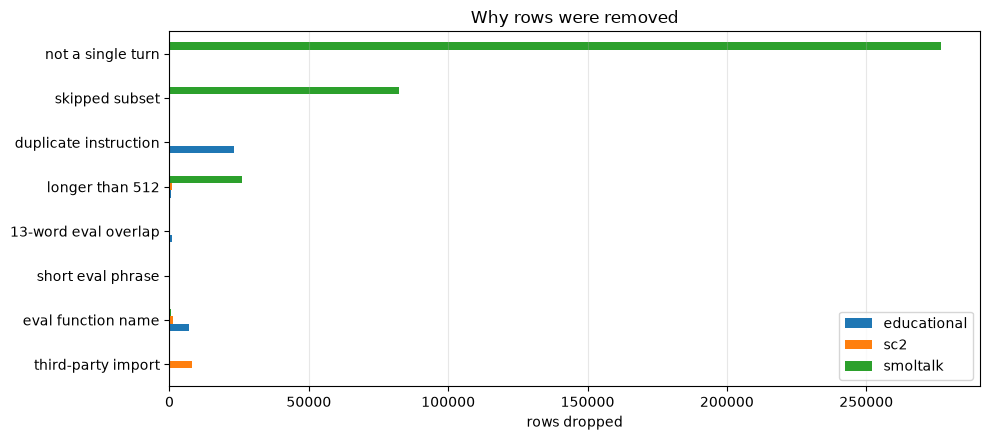

             third-party import  eval function name  short eval phrase  13-word eval overlap  longer than 512  duplicate instruction  skipped subset  not a single turn
educational                 271                6845                249                   891              392                  23083               0                  0
sc2                        7982                1389                  7                     5              804                      1               0                  0
smoltalk                      0                 441                  0                     0            26130                    168           82504             276976


In [8]:
DROP_LABELS = {
    "name": "eval function name",
    "shingle": "13-word eval overlap",
    "substring": "short eval phrase",
    "code": "copied eval solution",
    "import": "third-party import",
    "length": "longer than 512",
    "dup": "duplicate instruction",
    "shape": "not a single turn",
    "source": "skipped subset",
    "empty": "empty",
}

summary = []
for name in SOURCES:
    entry = manifest["sources"][name]
    dropped = sum(entry["drops"].values())
    summary.append(
        {
            "source": name,
            "seen": entry["seen"],
            "passed": entry["seen"] - dropped,
            "train": entry["kept_train"],
            "val": entry["kept_val"],
            "train_tokens": entry["tokens_train"],
        }
    )
summary = pd.DataFrame(summary).set_index("source")
print(summary.to_string())
print()
train_tokens = int(summary["train_tokens"].sum())
print(f"train tokens {train_tokens:,}  (~{train_tokens / 14_000 / 60:.0f} min/epoch at 14k tokens/s)")

drop = pd.DataFrame({name: manifest["sources"][name]["drops"] for name in SOURCES}).T
drop = drop.loc[:, drop.sum() > 0].rename(columns=DROP_LABELS)

fig, ax = plt.subplots(figsize=(10, 4.5))
drop.T.plot.barh(ax=ax, color=[COLORS[name] for name in drop.index])
ax.set(xlabel="rows dropped", title="Why rows were removed")
ax.grid(True, axis="x", alpha=0.3)
ax.legend(title=None)
plt.tight_layout()
plt.show()
print(drop.to_string())

## Mix

Code is most of the tokens. SmolTalk is there so the model also sees ordinary English replies in the same `<|user|>` / `<|assistant|>` layout.

examples
split        train   val
source                  
educational  84787  1760
sc2          39669   804
smoltalk     14698   302

tokens
split             train      val
source                          
educational  11,863,668  249,384
sc2          11,998,960  248,966
smoltalk      3,600,211   72,525


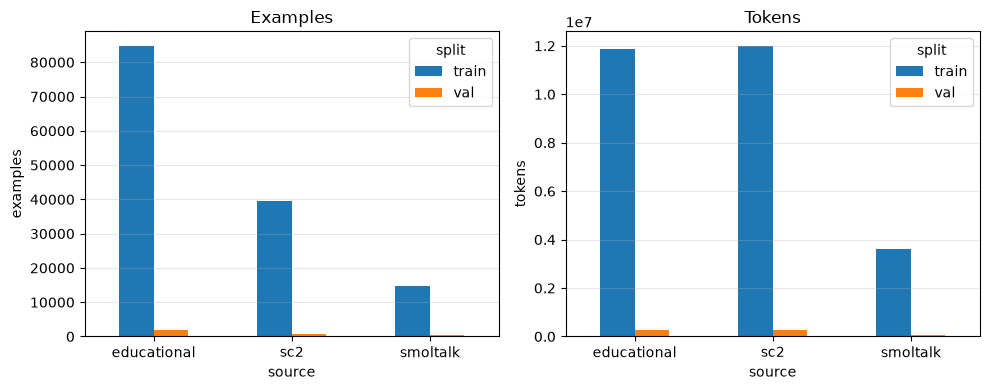

In [9]:
counts = df.groupby(["source", "split"]).size().unstack(fill_value=0)[ ["train", "val"] ]
tokens = df.groupby(["source", "split"])["n_tokens"].sum().unstack(fill_value=0)[ ["train", "val"] ]
print("examples")
print(counts.to_string())
print("\ntokens")
print(tokens.apply(lambda col: col.map(lambda n: f"{n:,}")).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
counts.plot.bar(ax=axes[0], rot=0, color=["C0", "C1"])
axes[0].set(ylabel="examples", title="Examples")
axes[0].grid(True, axis="y", alpha=0.3)
tokens.plot.bar(ax=axes[1], rot=0, color=["C0", "C1"])
axes[1].set(ylabel="tokens", title="Tokens")
axes[1].grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Lengths

Every example is at most 512 tokens, counting the special tokens. SmolTalk sits higher because a chat reply is a paragraph, while an educational answer is a short function.

             count  mean  10%  50%  90%  max
source                                      
educational  86547   140   62  121  243  512
sc2          40473   303  177  297  441  512
smoltalk     15000   245   78  249  413  512


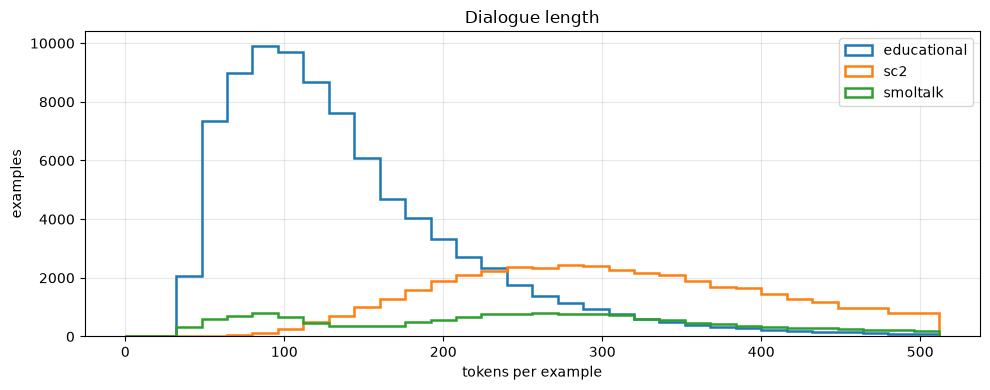

In [10]:
lengths = df.groupby("source")["n_tokens"].describe(percentiles=[0.1, 0.5, 0.9]).round(0)
print(lengths[["count", "mean", "10%", "50%", "90%", "max"]].astype(int).to_string())
assert df["n_tokens"].max() <= manifest["seq_len"]

fig, ax = plt.subplots(figsize=(10, 4))
bins = range(0, manifest["seq_len"] + 16, 16)
for name in SOURCES:
    ax.hist(
        df.loc[df["source"] == name, "n_tokens"],
        bins=bins,
        histtype="step",
        linewidth=1.8,
        label=name,
        color=COLORS[name],
    )
ax.set(xlabel="tokens per example", ylabel="examples", title="Dialogue length")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## SmolTalk subsets

The 15,000 cap is split evenly across the subsets that survived. Three of them fill that share, about 3,730 each. The two smaller subsets contribute every row that passed the filters.

subset
smol-summarize-5k            795
explore-instruct-rewrite    3014
openhermes-50k              3730
smol-summarize-20k          3730
smollm-rewrite-30k          3731


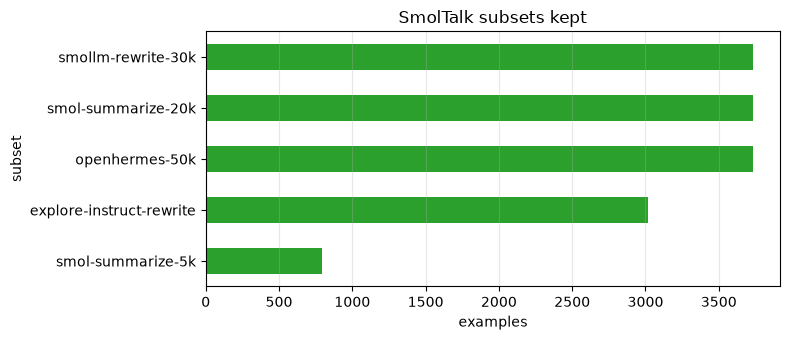

In [11]:
chat = df.loc[df["source"] == "smoltalk"]
subsets = chat.groupby("subset").size().sort_values(ascending=True)
print(subsets.to_string())

fig, ax = plt.subplots(figsize=(8, 3.5))
subsets.plot.barh(ax=ax, color="C2")
ax.set(xlabel="examples", title="SmolTalk subsets kept")
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## What the answers look like

Educational answers should be a function, and each one still carries the asserts it was checked with. sc2 answers are usually the longer explanation, with the function inside a fence.

In [12]:
def _show(row: pd.Series, limit: int = 700) -> None:
    print(f"--- {row['source']} {row['split']}  {row['n_tokens']} tokens")
    user = row["user"]
    assistant = row["assistant"]
    print(user[:limit] + (" ..." if len(user) > limit else ""))
    print()
    print(assistant[:limit] + (" ..." if len(assistant) > limit else ""))
    if isinstance(row.get("tests"), list) and row["tests"]:
        print()
        print("tests:", " | ".join(row["tests"][:3]))
    print()


code = df.loc[df["source"].isin(["educational", "sc2"])].copy()
code["fenced"] = code["assistant"].str.contains("```", regex=False)
code["starts_def"] = code["assistant"].str.lstrip().str.startswith("def ")
print(code.groupby("source")[["fenced", "starts_def"]].mean().round(3).to_string())

edu = df.loc[df["source"] == "educational"]
n_tests = edu["tests"].map(lambda tests: len(tests) if isinstance(tests, list) else 0)
print(f"\neducational tests per example: median {n_tests.median():.0f}, "
      f"min {n_tests.min()}, max {n_tests.max()}")

rng = df.sample(frac=1, random_state=1337)
for name in SOURCES:
    _show(rng.loc[rng["source"] == name].iloc[0])

             fenced  starts_def
source                         
educational   0.000       0.818
sc2           0.909       0.057

educational tests per example: median 3, min 3, max 70
--- educational train  94 tokens
Create a function that takes a list of strings and returns a dictionary whose keys are the lengths of the strings and values are lists of strings that have the same length.

def length_group(strings):
    result = {}
    for string in strings:
        length = len(string)
        if length not in result:
            result[length] = [string]
        else:
            result[length].append(string)
    return result

tests: assert length_group(["apple", "pear", "orange"]) == {5: ["apple"], 4: ["pear"], 6: ["orange"]} | assert length_group(["hello", "world", "python", "java"]) == {5: ["hello", "world"], 6: ["python"], 4: ["java"]} | assert length_group(["cat", "dog", "elephant", "tiger"]) == {3: ["cat", "dog"], 8: ["elephant"], 5: ["tiger"]}

--- sc2 train  296 tokens
Design 